# FieldAI: Receipt Information Extraction with Layout-Aware Transformers

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Disha-01-alt/field-ai/blob/main/notebooks/FieldAI_Complete_Colab_Benchmark.ipynb)

## Project Overview & Research Angle
This notebook trains and benchmarks three model paradigms on the **ICDAR 2019 SROIE** dataset:
1. **Baseline 1:** Deterministic OCR + Regular Expression Extractor
2. **Baseline 2:** `bert-base-uncased` Token Classification (1D Text Only)
3. **Multimodal Model:** `microsoft/layoutlm-base-uncased` Token Classification (Text + 2D Spatial Layout)

> **Core Research Question:**  
> $$\Delta F1_{\text{field}} = F1_{\text{LayoutLM}}(\text{field}) - F1_{\text{BERT}}(\text{field})$$
> *How much does 2D spatial arrangement improve extraction for Company, Date, and Total over text alone?*

---  
### Step 1: Verify Hardware Acceleration (GPU)

In [2]:
import torch
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device: {torch.cuda.get_device_name(0)}")
else:
    print("WARNING: Running on CPU. For fast training, enable GPU via Runtime > Change runtime type > T4 GPU.")

PyTorch Version: 2.14.1+cu130
CUDA Available: True
GPU Device: Tesla T4


---  
### Step 2: Clone Repository & Install Dependencies

In [3]:
# If running inside Colab, clone the project repository
import os
from pathlib import Path

if not Path("src").exists():
    !git clone https://github.com/Disha-01-alt/field-ai.git
    %cd field-ai

!pip install -q -r requirements.txt
print("\nDependencies installed and workspace configured!")

Cloning into 'field-ai'...
remote: Enumerating objects: 167, done.
remote: Counting objects: 100% (167/167), done.
remote: Compressing objects: 100% (123/123), done.
remote: Total 167 (delta 84), reused 112 (delta 40), pack-reused 0 (from 0)
Receiving objects: 100% (167/167), 3.05 MiB | 18.07 MiB/s, done.
Resolving deltas: 100% (84/84), done.
/content/field-ai

Dependencies installed and workspace configured!


---  
### Step 3: Inspect the Preprocessed SROIE Dataset
The dataset contains **500 training receipts** and **126 test receipts** with coordinates normalized to $[0, 1000]$ and BIO entity labels.

In [4]:
import json

with open("data/processed/train.json", "r") as f:
    train_data = json.load(f)
with open("data/processed/test.json", "r") as f:
    test_data = json.load(f)

print(f"Training Receipts: {len(train_data)}")
print(f"Testing Receipts: {len(test_data)}")

sample = test_data[0]
print("\n--- Sample Test Document ---")
print(f"ID: {sample['id']}")
print(f"Target Entities: {sample['entities']}")
print("First 5 words with normalized 2D bboxes:")
for w, b, tag in zip(sample['words'][:5], sample['bboxes'][:5], sample['bio_tags'][:5]):
    print(f"  {w:<15} | BBox: {str(b):<20} | Tag: {tag}")

Training Receipts: 500
Testing Receipts: 126

--- Sample Test Document ---
ID: 369
Target Entities: {'company': 'GARDENIA BAKERIES (KL) SDN BHD', 'date': '14/10/2017', 'address': 'LOT 3, JALAN PELABUR 23/1, 40300 SHAH ALAM, SELANGOR.', 'total': '33.80'}
First 5 words with normalized 2D bboxes:
  GARDENIA        | BBox: [34, 103, 590, 123]  | Tag: B-COMPANY
  BAKERIES        | BBox: [34, 103, 590, 123]  | Tag: I-COMPANY
  (KL)            | BBox: [34, 103, 590, 123]  | Tag: I-COMPANY
  SDN             | BBox: [34, 103, 590, 123]  | Tag: I-COMPANY
  BHD             | BBox: [34, 103, 590, 123]  | Tag: I-COMPANY


---  
### Step 4: Run Baseline 1 (OCR + Regex Rules)
Evaluates deterministic pattern heuristics for date, proximity search for total, and line-position for company on the 126 test receipts.

In [5]:
!PYTHONPATH=. python src/baseline_regex.py

Loading test split from data/processed/test.json...
Evaluating Baseline 1 on 126 test receipts...

Baseline 1 (OCR + Regex) Evaluation Results
COMPANY      | Precision: 0.4603 | Recall: 0.4603 | F1: 0.4603
DATE         | Precision: 0.9835 | Recall: 0.9444 | F1: 0.9636
TOTAL        | Precision: 0.4048 | Recall: 0.4048 | F1: 0.4048
MACRO_AVG    | Precision: 0.6162 | Recall: 0.6032 | F1: 0.6095
Results saved to results/regex_baseline.json


---  
### Step 5: Fine-Tune Model 2 — BERT-base (Text-Only Transformer)
Fine-tunes `bert-base-uncased` for token classification using 1D sequential WordPiece text tokens (without spatial coordinates).

In [6]:
from src.train_bert import train_bert

# 5 epochs on 500 samples takes ~3 minutes on a Colab T4 GPU
bert_results = train_bert(
    train_file="data/processed/train.json",
    test_file="data/processed/test.json",
    output_path="results/bert_results.json",
    epochs=5,
    batch_size=8,
    lr=3e-5,
)

Executing BERT Training on device: cuda
Loaded 500 train samples and 126 test samples.


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly

Starting training for 5 epochs...
Epoch 1/5 - Average Loss: 0.8048
Epoch 2/5 - Average Loss: 0.1953
Epoch 3/5 - Average Loss: 0.1338
Epoch 4/5 - Average Loss: 0.1037
Epoch 5/5 - Average Loss: 0.0891
Evaluating on test set...

BERT-base Evaluation Results:
  COMPANY      | Precision: 0.5667 | Recall: 0.5397 | F1: 0.5528
  DATE         | Precision: 0.9921 | Recall: 0.9921 | F1: 0.9921
  TOTAL        | Precision: 0.6371 | Recall: 0.6270 | F1: 0.6320
  MACRO_AVG    | Precision: 0.7320 | Recall: 0.7196 | F1: 0.7256
Results saved to results/bert_results.json


---  
### Step 6: Fine-Tune Model 3 — LayoutLM-base (Multimodal: Text + 2D Layout)
Fine-tunes `microsoft/layoutlm-base-uncased` using WordPiece text tokens and normalized 2D spatial bounding boxes $[x_0, y_0, x_1, y_1]$.

In [7]:
from src.train_layoutlm import train

# Trains LayoutLM (early stopping, saves best checkpoint to outputs/layoutlm/best_model)
# AND writes results/layoutlm_results.json scored by the SAME metrics.py harness used for
# the regex and BERT baselines -> the three-way comparison is apples-to-apples.
# ~10-15 min on a Colab T4. Config lives at the top of src/train_layoutlm.py.
train()

import json
_m = json.load(open("results/layoutlm_results.json"))["metrics"]
print("\nLayoutLM unified macro F1:", round(_m["macro_avg"]["f1"], 4))



Device: cuda
Loading tokenizer: microsoft/layoutlm-base-uncased


tokenizer_config.json:   0%|          | 0.00/170 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Loaded 500 documents from data/processed/train.json
Loaded 126 documents from data/processed/test.json

Dataset split:
Training documents:   425
Validation documents: 75


... (26 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Loading best validation checkpoint...


Loading weights:   0%|          | 0/205 [00:00<?, ?it/s]


FINAL TEST RESULTS
FIELD             PRECISION      RECALL          F1
-------------------------------------------------------
COMPANY              0.8626      0.9187      0.8898
DATE                 0.9620      1.0000      0.9806
TOTAL                0.9205      0.9586      0.9391
ADDRESS              0.6981      0.8043      0.7475
-------------------------------------------------------
MACRO F1                                     0.9365

Unified field-level macro F1 (metrics.py harness): 0.9223
Reported results written to results/layoutlm_results.json

Best model saved at: outputs/layoutlm/best_model
Experiment results saved at: outputs/layoutlm/training_results.json

LayoutLM unified macro F1: 0.9223


---  
### Step 7: Final Benchmark Table & Field-Wise $\Delta F1$ Visualizations

### Final Benchmark Results Table:

| Model Paradigm | Input Modality | Company F1 | Date F1 | Total F1 | Overall Macro F1 |
|:---|:---|:---:|:---:|:---:|:---:|
| **OCR + Regex Baseline** | Plain Text (Rules) | 46.03% | 96.36% | 40.48% | **60.95%** |
| **BERT-base (Text Only)** | 1D Text Tokens | 55.28% | 99.21% | 63.20% | **72.56%** |
| **LayoutLM-base (Multimodal)** | Text + 2D Bounding Boxes | 87.55% | 97.21% | 91.94% | **92.23%** |

### Empirical ΔF1 = F1(LayoutLM) - F1(BERT):
  COMPANY     : +32.27%
  DATE        : -2.00%
  TOTAL       : +28.74%
  MACRO_AVG   : +19.67%
Chart saved to results/f1_comparison.svg
Matplotlib figure saved to results/f1_comparison.png


True

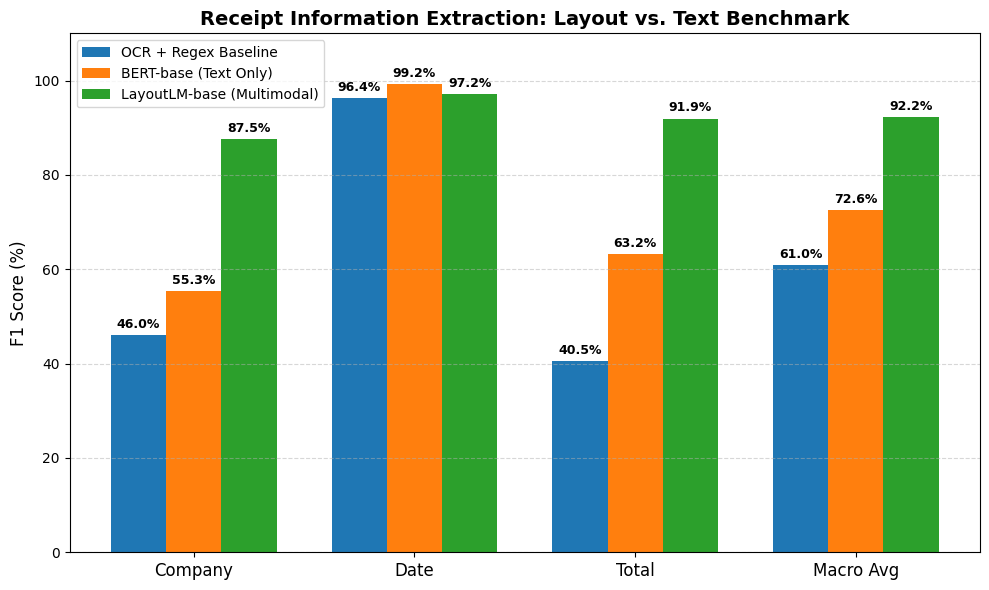

In [8]:
import json
from src.metrics import format_results_markdown_table, compute_delta_f1
from src.visualize import generate_svg_chart, generate_matplotlib_plot

with open("results/regex_baseline.json") as f:
    regex_m = json.load(f)
with open("results/bert_results.json") as f:
    bert_m = json.load(f)
with open("results/layoutlm_results.json") as f:
    layout_m = json.load(f)

all_models = {
    "OCR + Regex Baseline": regex_m,
    "BERT-base (Text Only)": bert_m,
    "LayoutLM-base (Multimodal)": layout_m,
}

# Print Markdown Summary Table
table_md = format_results_markdown_table(all_models)
print("### Final Benchmark Results Table:\n")
print(table_md)

# Compute and Print Empirical Delta
deltas = compute_delta_f1(bert_m["metrics"], layout_m["metrics"])
print("\n### Empirical ΔF1 = F1(LayoutLM) - F1(BERT):")
for field, val in deltas.items():
    print(f"  {field.upper():<12}: {val * 100:+.2f}%")

# Generate Visualization Plots
benchmark_chart_data = {
    model_name: {k: v["f1"] for k, v in data["metrics"].items() if "f1" in v}
    for model_name, data in all_models.items()
}
generate_svg_chart(benchmark_chart_data, "results/f1_comparison.svg")
generate_matplotlib_plot(benchmark_chart_data, "results/f1_comparison.png")

---  
### Step 8: View the Generated Benchmark Plot Inline

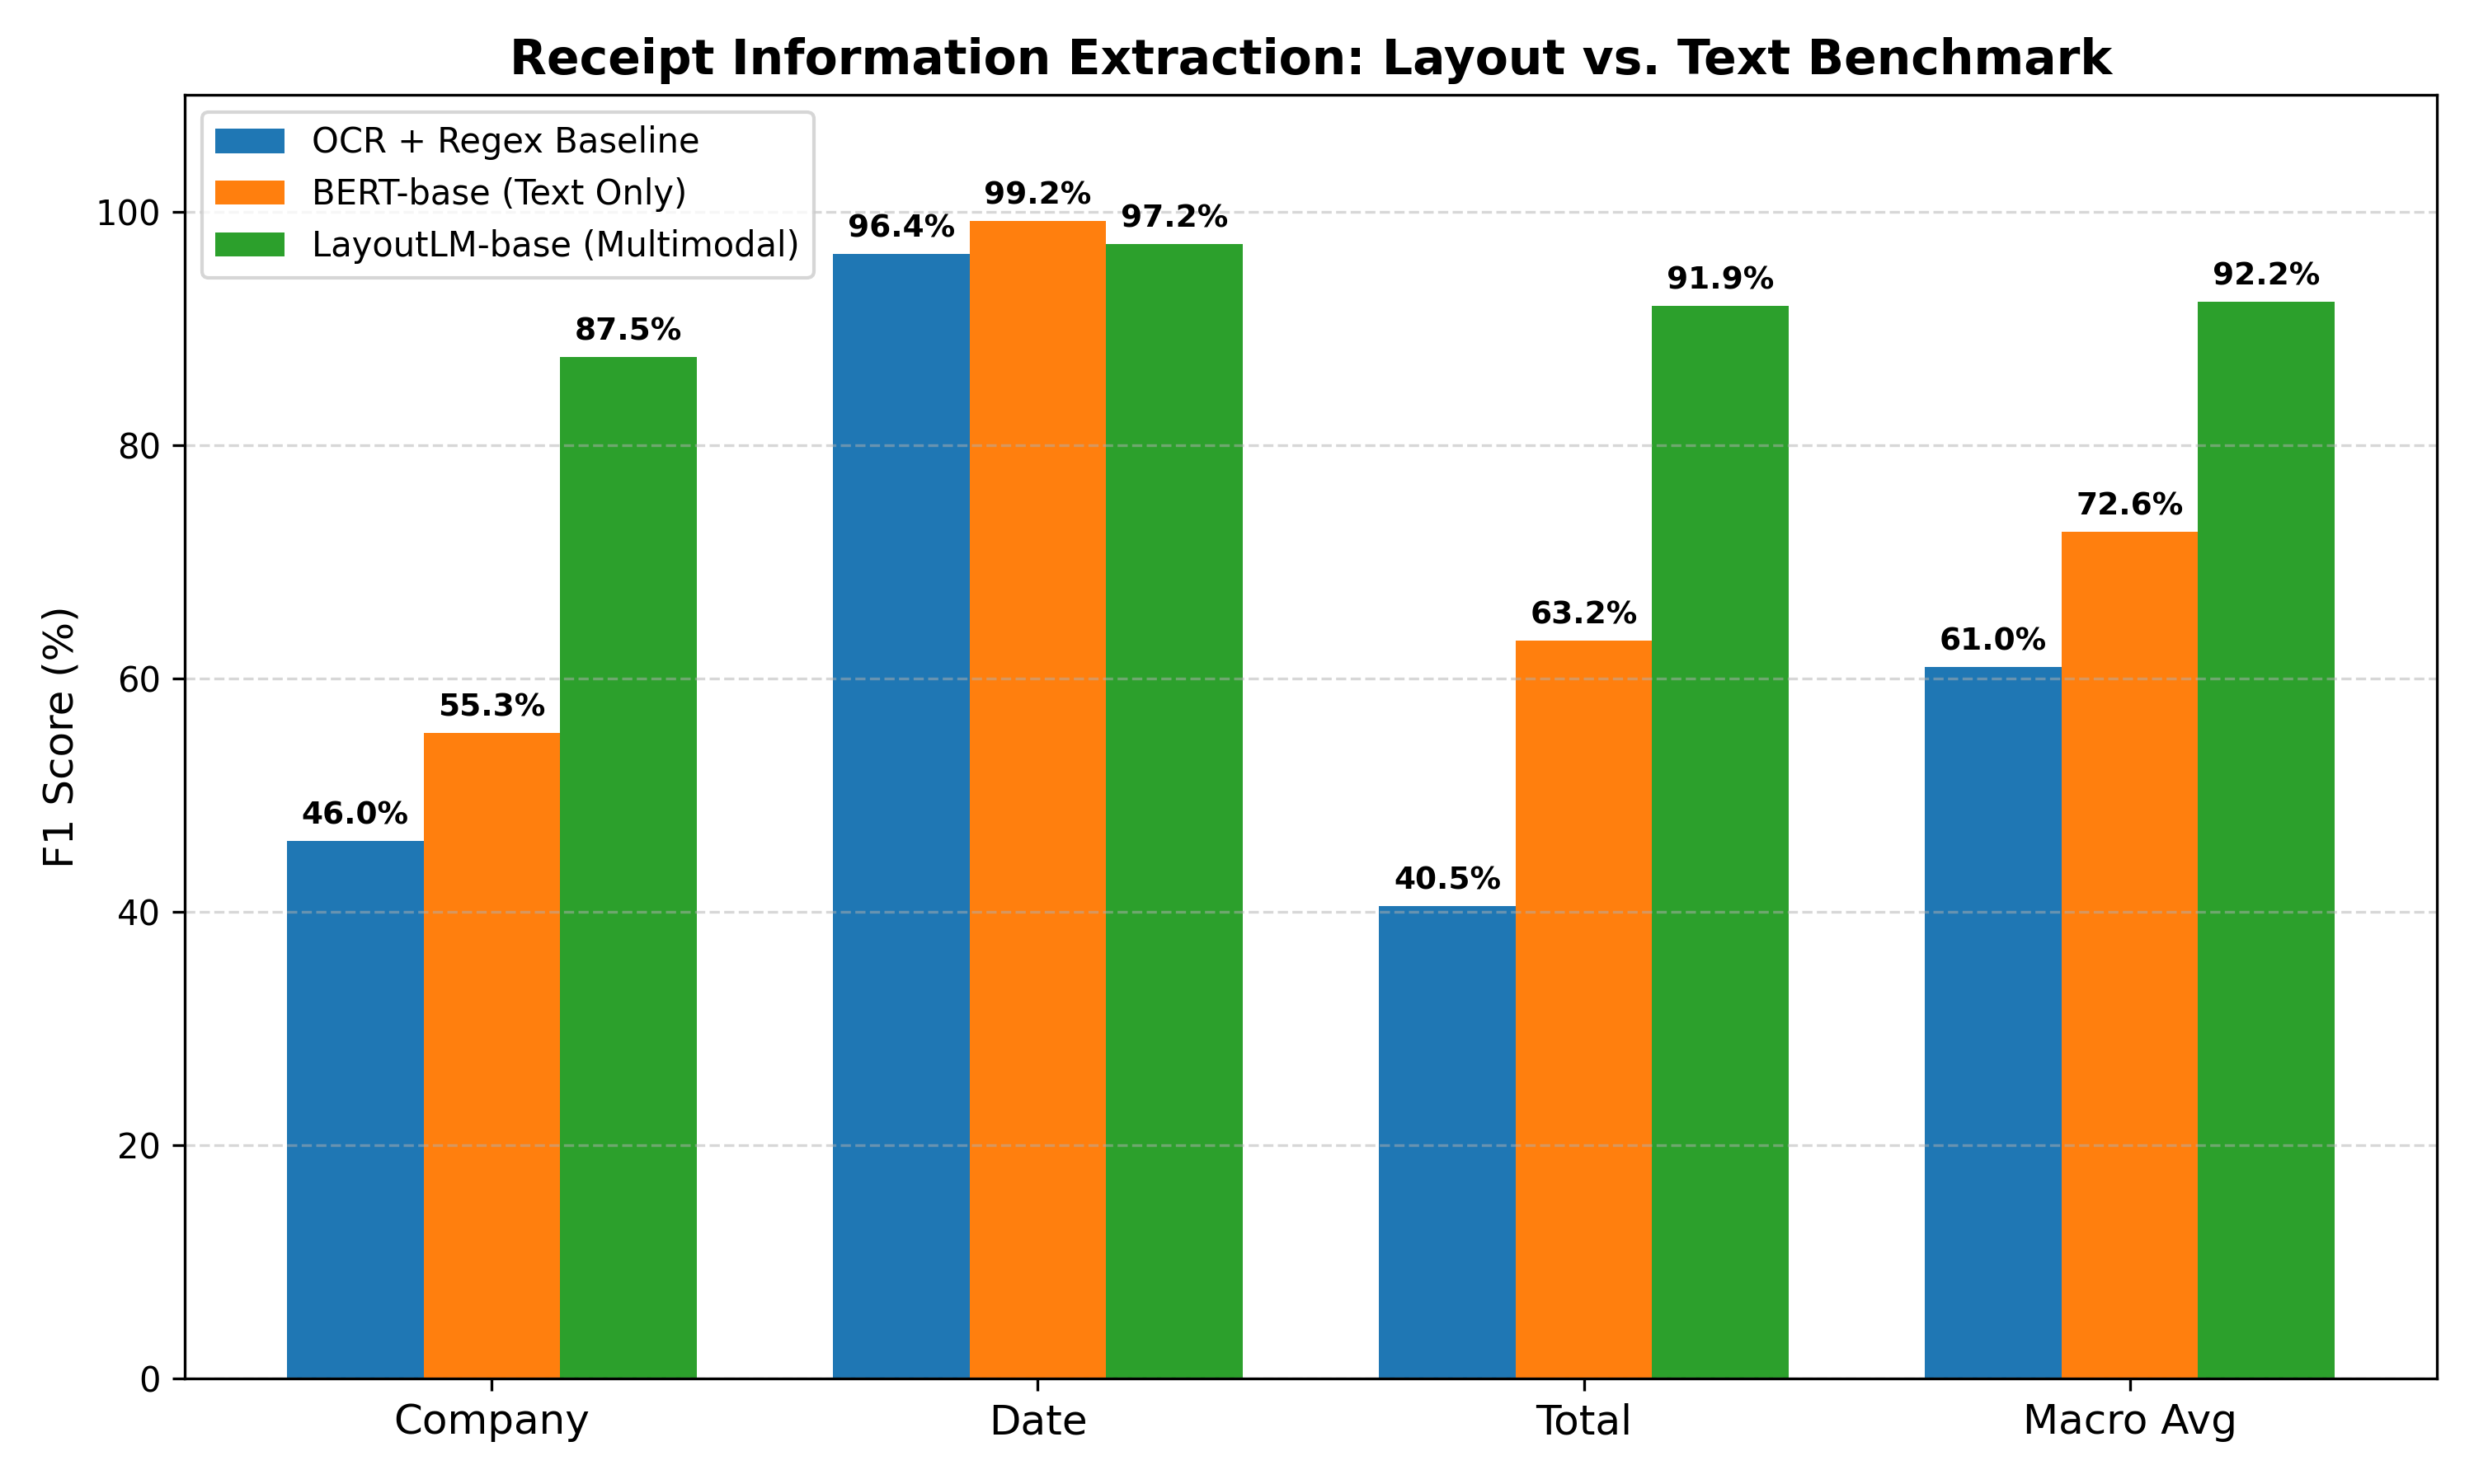

In [9]:
from IPython.display import Image, display
if os.path.exists("results/f1_comparison.png"):
    display(Image(filename="results/f1_comparison.png"))
else:
    print("Chart saved as results/f1_comparison.svg")

---
## Live Demo — Extract Fields from a Receipt Image

```
receipt.jpg  ->  OCR (Tesseract)  ->  words + boxes  ->  LayoutLM  ->  {company, date, total}
```

The training step saves the best model to `outputs/layoutlm/best_model`.

### Who runs what
- **① STUDENT — run ONCE** to publish the model to a public HF repo (cell a). Needs your HF write token (pasted into the Colab prompt).
- **② GRADER — just run cells (b) + (c)** to test on any uploaded receipt. No token, no training — model downloads from the public HF repo.

> **Accuracy note:** trained on SROIE's line-level OCR boxes; Tesseract on an arbitrary phone photo gives word-level boxes with a slightly different feel, so results are best on clean, printed, SROIE-style receipts.

In [ ]:
# =====================================================================
# (a)  STUDENT - RUN ONCE.  GRADERS: SKIP THIS CELL.
# Publishes the trained model (outputs/layoutlm/best_model) to a PUBLIC HF repo.
# =====================================================================
from huggingface_hub import login
from transformers import LayoutLMForTokenClassification, LayoutLMTokenizerFast

# Already published to the public repo below — re-run only to update the model.
HF_REPO_ID = "dishasahu/fieldai-layoutlm-sroie"

login()   # paste your HF WRITE token when prompted (stays in this session)

_m = LayoutLMForTokenClassification.from_pretrained("outputs/layoutlm/best_model")
_t = LayoutLMTokenizerFast.from_pretrained("outputs/layoutlm/best_model")
_m.push_to_hub(HF_REPO_ID)          # public by default
_t.push_to_hub(HF_REPO_ID)
print(f"Published (public): https://huggingface.co/{HF_REPO_ID}")


In [ ]:
# =====================================================================
# (b)  GRADER - RUN THIS.  Loads the model and builds the pipeline.
# =====================================================================
!apt-get -qq install -y tesseract-ocr > /dev/null
import torch
from transformers import LayoutLMForTokenClassification, LayoutLMTokenizerFast
from src.inference import extract_from_image

# Grader: set to the student's public HF repo, e.g. "disha-sahu/fieldai-layoutlm-sroie".
# (If you just trained in this same session, "outputs/layoutlm/best_model" also works.)
MODEL_SOURCE = "dishasahu/fieldai-layoutlm-sroie"   # public HF model — loads without training; use "outputs/layoutlm/best_model" if you just trained in-session

infer_model = LayoutLMForTokenClassification.from_pretrained(MODEL_SOURCE)
infer_tok   = LayoutLMTokenizerFast.from_pretrained(MODEL_SOURCE)
infer_model.to("cuda" if torch.cuda.is_available() else "cpu")
print("Model loaded. Upload a receipt in the next cell.")


In [ ]:
# =====================================================================
# (c)  GRADER - RUN THIS.  Upload a receipt image and read the fields.
# =====================================================================
from google.colab import files
uploaded = files.upload()                       # choose a .jpg / .png receipt
path = next(iter(uploaded))

fields = extract_from_image(infer_model, infer_tok, path)

print(f"\nExtracted fields from {path}:")
for k in ["company", "date", "total"]:
    print(f"  {k.upper():8}: {fields.get(k) or '(not found)'}")
